# Student Pass Prediction Using Logistic Regression

## Introduction
This project uses Machine Learning to predict whether
a student will pass or fail based on study hours,
attendance percentage and previous examination marks.

The Logistic Regression algorithm is used for
binary classification.

## Step 1: Import Required Libraries

In this step, we import the Python libraries required
for dataset creation, data manipulation, visualization
and machine learning model development.

In [262]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score
)

print("All libraries imported successfully!")

All libraries imported successfully!


## Step 2: Dataset Creation

We create a synthetic dataset containing 500 student
records.

The dataset includes study hours, attendance and
previous marks. The target variable is Result.

0 represents Fail and 1 represents Pass.

In [263]:
np.random.seed(42)

n = 500

study_hours = np.random.uniform(0, 10, n)

attendance = np.random.uniform(40, 100, n)

previous_marks = np.random.uniform(20, 100, n)

# Calculate a linear score
z = (
    -8
    + 0.45 * study_hours
    + 0.045 * attendance
    + 0.065 * previous_marks
)

# Convert score into probability using sigmoid
probability = 1 / (1 + np.exp(-z))

# Generate binary target values
result = np.random.binomial(1, probability)

# Create DataFrame
df = pd.DataFrame({
    "Study_Hours": study_hours.round(2),
    "Attendance": attendance.round(2),
    "Previous_Marks": previous_marks.round(2),
    "Result": result
})

print("Dataset created successfully!")

df.head()

Dataset created successfully!


,Study_Hours,Attendance,Previous_Marks,Result
0,3.75,81.89,34.81,0
1,9.51,72.17,63.35,1
2,7.32,58.57,89.84,1
3,5.99,88.83,78.58,1
4,1.56,81.08,84.52,1


## Step 3: Dataset Exploration

In this step, we inspect the dataset using Pandas.

We check the first five records, dataset shape,
column names, data types and summary statistics.

In [264]:
print("First Five Records:")
display(df.head())

print("Dataset Shape:")
print(df.shape)

print("Dataset Information:")
df.info()

print("Statistical Summary:")
display(df.describe())

First Five Records:


,Study_Hours,Attendance,Previous_Marks,Result
0,3.75,81.89,34.81,0
1,9.51,72.17,63.35,1
2,7.32,58.57,89.84,1
3,5.99,88.83,78.58,1
4,1.56,81.08,84.52,1


Dataset Shape:
(500, 4)
Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Study_Hours     500 non-null    float64
 1   Attendance      500 non-null    float64
 2   Previous_Marks  500 non-null    float64
 3   Result          500 non-null    int64  
dtypes: float64(3), int64(1)
memory usage: 15.8 KB
Statistical Summary:


,Study_Hours,Attendance,Previous_Marks,Result
count,500.000000,500.000000,500.000000,500.000000
mean,4.985540,68.916960,61.404700,0.696000
std,2.986884,17.129535,23.775271,0.460443
min,0.050000,40.280000,20.400000,0.000000
25%,2.415000,53.750000,39.295000,0.000000
50%,5.130000,68.305000,63.180000,1.000000
75%,7.565000,83.577500,82.190000,1.000000
max,9.930000,99.980000,99.950000,1.000000


## Step 4: Data Cleaning

We check whether the dataset contains missing values
or duplicate records.

This helps us ensure that the dataset is ready
for machine learning.

In [265]:
print("Missing Values:")
print(df.isnull().sum())

print("Duplicate Records:")
print(df.duplicated().sum())

df = df.drop_duplicates()

print("Dataset cleaning completed!")

Missing Values:
Study_Hours       0
Attendance        0
Previous_Marks    0
Result            0
dtype: int64
Duplicate Records:
0
Dataset cleaning completed!


## Step 5: Exploratory Data Analysis

We visualize the student dataset using graphs.

Histograms show the distribution of numerical features.
A count plot displays the number of Pass and Fail cases.
A correlation heatmap shows relationships between variables.

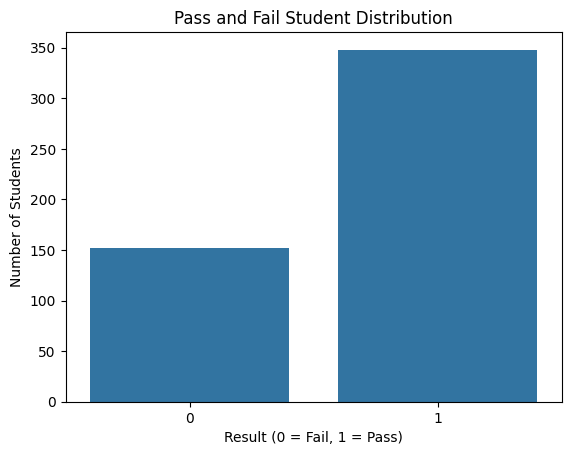

In [266]:
sns.countplot(data=df, x="Result")

plt.title("Pass and Fail Student Distribution")
plt.xlabel("Result (0 = Fail, 1 = Pass)")
plt.ylabel("Number of Students")

plt.show()

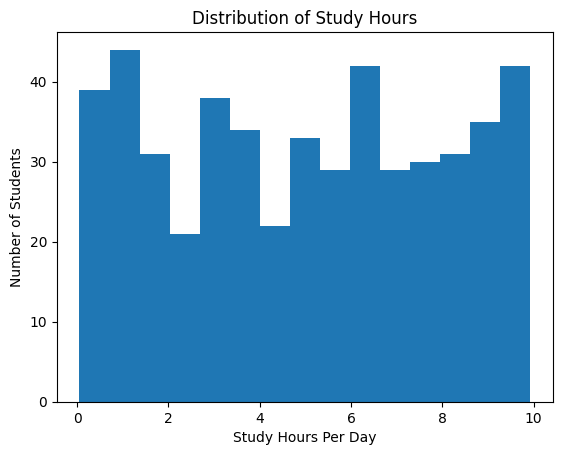

In [267]:
plt.hist(df["Study_Hours"], bins=15)

plt.title("Distribution of Study Hours")
plt.xlabel("Study Hours Per Day")
plt.ylabel("Number of Students")

plt.show()

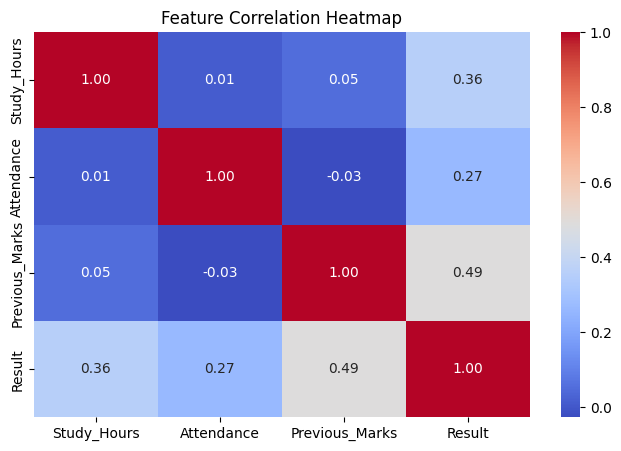

In [268]:
plt.figure(figsize=(8, 5))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Feature Correlation Heatmap")
plt.show()

## Step 6: Feature Selection

We separate the dataset into independent and dependent
variables.

Independent variables:
Study_Hours, Attendance and Previous_Marks.

Dependent variable:
Result (Pass or Fail).

In [269]:
X = df[
    ["Study_Hours", "Attendance", "Previous_Marks"]
]

y = df["Result"]

print("Input Features:")
display(X.head())

print("Target Variable:")
display(y.head())

Input Features:


,Study_Hours,Attendance,Previous_Marks
0,3.75,81.89,34.81
1,9.51,72.17,63.35
2,7.32,58.57,89.84
3,5.99,88.83,78.58
4,1.56,81.08,84.52


Target Variable:


,Result
0,0
1,1
2,1
3,1
4,1


## Step 7: Train-Test Split

We divide the dataset into two parts.

80% of the data is used for model training.
20% of the data is used for model testing.

Stratified splitting maintains the approximate
proportion of Pass and Fail cases in both sets.

In [270]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (400, 3)
Testing Data: (100, 3)


## Step 8: Logistic Regression Model Training

Logistic Regression is a supervised machine learning
algorithm used for binary classification.

It uses the sigmoid function to convert a linear score
into a probability between 0 and 1.

We use StandardScaler to standardize input features
and LogisticRegression to train the model.

The model learns patterns from the training dataset.

In [271]:
model = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(max_iter=1000))
])

model.fit(X_train, y_train)

print("Logistic Regression Model Trained Successfully!")

Logistic Regression Model Trained Successfully!


## Step 9: Model Prediction

After training, we use the testing dataset to
predict student results.

The model predicts:
0 = Fail
1 = Pass

We also calculate the probability of passing.

In [272]:
y_pred = model.predict(X_test)

y_probability = model.predict_proba(X_test)[:, 1]

prediction_results = pd.DataFrame({
    "Actual Result": y_test.values,
    "Predicted Result": y_pred,
    "Pass Probability": y_probability.round(3)
})

display(prediction_results.head(10))

,Actual Result,Predicted Result,Pass Probability
0,1,1,0.867
1,1,1,0.882
2,1,1,0.944
3,0,1,0.817
4,0,0,0.178
5,1,0,0.045
6,1,1,0.979
7,0,1,0.644
8,1,1,0.575
9,1,1,0.986


## Step 10: Model Evaluation

We evaluate the trained model using different
classification performance metrics.

Accuracy measures overall correct predictions.
Precision measures the correctness of positive predictions.
Recall measures how many actual positive cases are identified.
F1-score is the harmonic mean of precision and recall.

In [273]:
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(y_test, y_pred, zero_division=0)

recall = recall_score(y_test, y_pred, zero_division=0)

f1 = f1_score(y_test, y_pred, zero_division=0)

print("Model Performance")

print("Accuracy:", round(accuracy * 100, 2), "%")
print("Precision:", round(precision, 3))
print("Recall:", round(recall, 3))
print("F1 Score:", round(f1, 3))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Model Performance
Accuracy: 88.0 %
Precision: 0.882
Recall: 0.957
F1 Score: 0.918

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.70      0.78        30
           1       0.88      0.96      0.92        70

    accuracy                           0.88       100
   macro avg       0.88      0.83      0.85       100
weighted avg       0.88      0.88      0.88       100



## Step 11: Confusion Matrix

A confusion matrix compares actual results with
predicted results.

It shows:
True Positive (TP)
True Negative (TN)
False Positive (FP)
False Negative (FN)

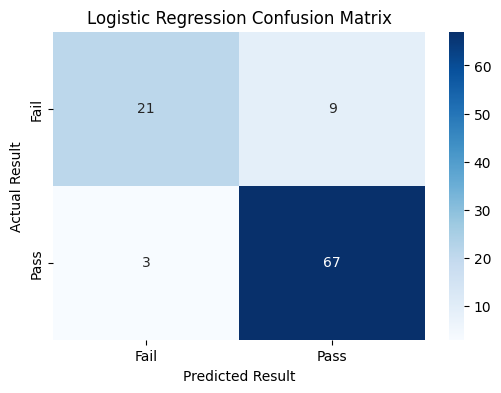

In [274]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fail", "Pass"],
    yticklabels=["Fail", "Pass"]
)

plt.xlabel("Predicted Result")
plt.ylabel("Actual Result")

plt.title("Logistic Regression Confusion Matrix")

plt.show()

## Step 12: ROC Curve

The ROC curve shows the relationship between
True Positive Rate and False Positive Rate
at different classification thresholds.

AUC measures the model's ability to distinguish
between the two classes.

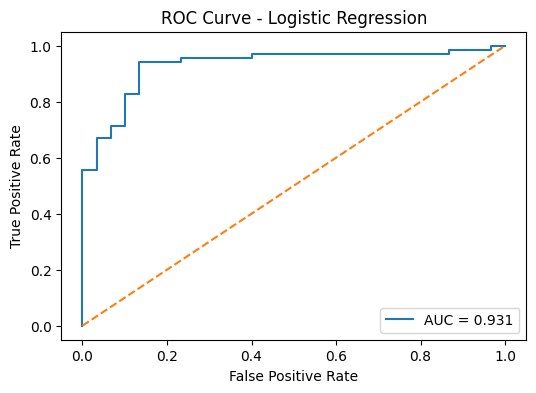

ROC-AUC Score: 0.931


In [275]:
fpr, tpr, thresholds = roc_curve(
    y_test,
    y_probability
)

auc = roc_auc_score(y_test, y_probability)

plt.figure(figsize=(6, 4))

plt.plot(fpr, tpr, label=f"AUC = {auc:.3f}")

plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve - Logistic Regression")

plt.legend()
plt.show()

print("ROC-AUC Score:", round(auc, 3))

## Step 13: New Student Prediction

Finally, we use the trained model to predict
the result of a new student.

The user provides study hours, attendance and
previous marks.

The model displays the predicted result and
probability of passing.

In [276]:
new_student = pd.DataFrame({
    "Study_Hours": [6],
    "Attendance": [85],
    "Previous_Marks": [75]
})

prediction = model.predict(new_student)

pass_probability = model.predict_proba(new_student)[0][1]

print("New Student Details:")
display(new_student)

print("Pass Probability:", round(pass_probability * 100, 2), "%")

if prediction[0] == 1:
    print("Predicted Result: PASS")
else:
    print("Predicted Result: FAIL")

New Student Details:


,Study_Hours,Attendance,Previous_Marks
0,6,85,75


Pass Probability: 97.78 %
Predicted Result: PASS


## Step 14: Save the Trained Model

We save the trained Logistic Regression pipeline
using Joblib.

This allows us to reuse the trained model later
without training it again.

In [277]:
import joblib

joblib.dump(model, "student_pass_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [278]:
from google.colab import files

files.download("student_pass_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [279]:
df.to_csv("student_dataset.csv", index=False)

In [280]:
files.download("student_dataset.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>